In [1]:
# Import general libraries

import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Import libraries for interactive graphs

import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

# **1.0 - Data Cleaning**

### 1.1 - Checking "groceries items"

In [2]:
df_groceries = pd.read_csv("us_average_prices_monthly (1.csv", sep=None, engine="python")

# Convert dates to datetime for consistent monthly alignment across datasets.

df_groceries["date"] = pd.to_datetime(df_groceries["date"])

# Focus on January 2015 through December 2025 (11 calendar years).

# Filtering data.

df_groceries = df_groceries[df_groceries["date"] < "2026-01-01"]

# Creating pivot table.

df_groceries__items = pd.pivot_table(df_groceries, values="price", index='date' , columns="item")

# Checking null values.

df_groceries__items.isna().sum().sort_values(ascending=False)

# Calculate the proportion of missing monthly prices for each item.

df_groceries__items.isna().mean().sort_values(ascending=False)

# Retain items with at most 9% missing observations (up to 11 of 132 months).
# This is a project-specific threshold, not a universal rule; 50 of 74 items remain.
# Note that overall completeness does not guarantee complete coverage at both endpoints.

df_groceries__items = df_groceries__items.loc[:, df_groceries__items.isna().mean() <= 0.09]

# Recheck missingness after filtering items:

df_groceries__items.isna().mean().sort_values(ascending=False)

# Examine missingness by month; many items are missing exactly one observation.

df_groceries__items.isna().sum(axis=1).sort_values(ascending=False)

# October 2025 is missing 47 of the 50 retained item prices.
# Fill internal gaps by linear interpolation; do not extrapolate at series endpoints.
# October 2025 estimates are especially uncertain and should be flagged in our presenation.

df_groceries__items = df_groceries__items.interpolate(method="linear", limit_area="inside")

# Verify missing values after interpolation. Preserve the original long-form

df_groceries__items.isna().sum()

item
All Ham (Excluding Canned Ham and Luncheon Slices)           0
All Other Pork (Excluding Canned Ham and Luncheon Slices)    0
All Pork Chops                                               0
All Uncooked Beef Roasts                                     0
All Uncooked Beef Steaks                                     0
All Uncooked Other Beef (Excluding Veal)                     0
All uncooked ground beef                                     0
American processed cheese                                    0
Automotive diesel fuel                                       0
Bacon, sliced                                                0
Bananas                                                      0
Beans, dried, any type, all sizes                            0
Bread, white, pan                                            0
Bread, whole wheat, pan                                      0
Cheddar cheese, natural                                      0
Chicken breast, boneless                          

### 1.1.1 - Creating a dataframe for categories.

In [3]:
# Creating pivot table.

df_categories = pd.pivot_table(df_groceries, values="price", index='date' , columns="category")

# Checking null values.

df_categories.isna().sum().sort_values(ascending=False)

# Calculate the proportion of missing monthly prices for each item.

df_categories.isna().mean().sort_values(ascending=False)

# Retain items with at most 9% missing observations.
# Note that overall completeness does not guarantee complete coverage at both endpoints.

df_categories = df_categories.loc[:, df_categories.isna().mean() <= 0.09]

# Recheck missingness after filtering items:

df_categories.isna().mean().sort_values(ascending=False)

# Same case from the items dataset. 
# Fill internal gaps by linear interpolation; do not extrapolate at series endpoints.
# October 2025 estimates are especially uncertain and should be flagged in our presentation.

df_categories = df_categories.interpolate(method="linear", limit_area="inside")

# Verify missing values after interpolation. Preserve the original long-form

df_categories.isna().sum()

category
Bakery and grains       0
Beef                    0
Dairy and fats          0
Drinks                  0
Eggs                    0
Energy                  0
Fruit                   0
Meat, broad category    0
Pantry and snacks       0
Pork and deli           0
Poultry                 0
Vegetables              0
dtype: int64

### 1.2 - Checking "Consumer Price Index"

In [4]:
df_index = pd.read_csv("Consumer_Price_Index.csv", sep=None, engine="python")

# Checking data type.

df_index.info()

# Transforming "observation_date" into date type.

df_index["observation_date"] = pd.to_datetime(df_index["observation_date"])
df_index.info()

# Setting new columns names.

columns = {
    "observation_date": "date",
    "CPIULFSL": "Consumer_Price_Index"}

df_index.rename(columns=columns, inplace=True)

# Filtering Data (2015-2025)

df_index = df_index[(df_index['date'] > "2014-12-01") & (df_index['date'] < "2026-01-01")]
df_index

# Checking missing values.

df_index.isna().sum()

# Checking which month is null.

df_index[df_index["Consumer_Price_Index"].isna()]

# October 2025 is missing in the CPI-excluding-food series (CPIULFSL).
# Estimate the missing index observation by linear interpolation. Highlight this situation in our presentation. 

df_index = df_index.interpolate(method="linear", limit_area="inside")
df_index.isna().sum()

# Setting "date" as the index of the dataset.

df_index = df_index.set_index("date")
df_index

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 957 entries, 0 to 956
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  957 non-null    object 
 1   CPIULFSL          956 non-null    float64
dtypes: float64(1), object(1)
memory usage: 15.1+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 957 entries, 0 to 956
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   observation_date  957 non-null    datetime64[ns]
 1   CPIULFSL          956 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 15.1 KB


,Consumer_Price_Index
date,
2015-01-01,232.969
2015-02-01,233.611
2015-03-01,234.411
2015-04-01,234.707
2015-05-01,235.571
...,...
2025-08-01,320.497
2025-09-01,321.478
2025-10-01,321.925


### 1.3 - Checking "Average Wage"

In [5]:
df_wage = pd.read_csv("Average_Hourly_Wages.csv", sep=None, engine="python")

# Checking Data type

df_wage.info()

# Transforming "date" into date time. 

df_wage["observation_date"] = pd.to_datetime(df_wage["observation_date"])
df_wage.info()

# Setting new column names.

columns_wage = {
    "observation_date": "date",
    "CES0500000003": "Average_Hourly_Wage"
}

df_wage.rename(columns=columns_wage, inplace=True)

# Filtering Data (2015 - 2025).

df_wage = df_wage[(df_wage["date"] > "2014-12-01") & (df_wage["date"] < "2026-01-01")]
df_wage

# Checking missing values.

df_wage.isna().sum()

# Setting "date" as the index for the dataset.

df_wage = df_wage.set_index("date")
df_wage

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 247 entries, 0 to 246
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  247 non-null    object 
 1   CES0500000003     247 non-null    float64
dtypes: float64(1), object(1)
memory usage: 4.0+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 247 entries, 0 to 246
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   observation_date  247 non-null    datetime64[ns]
 1   CES0500000003     247 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 4.0 KB


,Average_Hourly_Wage
date,
2015-01-01,24.74
2015-02-01,24.79
2015-03-01,24.85
2015-04-01,24.89
2015-05-01,24.97
...,...
2025-08-01,36.62
2025-09-01,36.70
2025-10-01,36.85


# **2.0 - Merging datasets (Consumer Price Index and Average Wage)**

In [6]:
# Join all three datasets on their monthly date indexes (inner join).
# Confirm the result has the expected 132 months and 52 columns, and check missing values.

df_join = [df_index, df_wage]

df_project_items = df_groceries__items.join(df_join, how="inner")
df_project_items.isna().sum()

# Join all three datasets for categories.
# Confirm the result has the expected 132 months and 52 columns, and check missing values.

df_join_cat = [df_index, df_wage]
df_project_categories = df_categories.join(df_join_cat, how="inner")
df_project_categories.isna().sum()

# Both datasets were created from the same original grocery dataset.
# The 9% missing-value threshold was applied independently to items
# and categories, followed by linear interpolation.
# Category averages may include items excluded from the item-level dataset.
# I can change it if you want to. 

Bakery and grains       0
Beef                    0
Dairy and fats          0
Drinks                  0
Eggs                    0
Energy                  0
Fruit                   0
Meat, broad category    0
Pantry and snacks       0
Pork and deli           0
Poultry                 0
Vegetables              0
Consumer_Price_Index    0
Average_Hourly_Wage     0
dtype: int64

In [7]:
# ============================================================
# NOTES
# ============================================================

# 1. DATASETS
# Two merged datasets were created:
# df_project_items: Monthly prices for individual items, CPI, and hourly wages.
# df_project_categories: Monthly category-level average prices, CPI, and hourly wages.
# Both datasets cover January 2015 through December 2025.

# 2. GROCERY CATEGORIES
# Category prices were calculated using the mean of individual item prices.
# Since products have different units, these averages should not be interpreted
# as representative grocery costs.
# Consider using percentage changes or normalized price indexes for comparisons.

# 3. FOOD VS. NON-FOOD ITEMS
# The original dataset includes gasoline, electricity, fuel oil, and other
# non-food products. Should we separate these when conducting grocery-specific analyses?

# 4. INFLATION RATE
# Consumer_Price_Index represents CPI excluding food (CPIULFSL), not inflation.
# We have to calculate month-over-month or year-over-year percentage changes
# before conducting regression or correlation analyses.

# 5. WAGE GROWTH
# Average_Hourly_Wage represents hourly earnings in dollars.
# Consider calculating percentage changes to compare wage growth with
# inflation and grocery price increases.

# 6. INTERPOLATED VALUES
# Missing observations were estimated using linear interpolation.
# October 2025 had substantial missing data, particularly for individual items.
# Results involving interpolated observations should be interpreted cautiously.

# **3.0 - Data Analysis**
This segment will provide you with answers to five queries concerning food costs, inflation and income. To explore the links between these phenomena, we will utilize the subset, comparison and statistics techniques within the time frame from January, 2015 to December, 2025.

In [9]:
category_palette = px.colors.qualitative.Safe

category_columns = [
    column for column in df_project_categories.columns
    if column not in [
        "Consumer_Price_Index",
        "Average_Hourly_Wage"
    ]
]

category_colors = {
    category: category_palette[i % len(category_palette)]
    for i, category in enumerate(category_columns)
}

### Question 1: Which grocery categories experienced the highest price increases between 2015 and 2025?

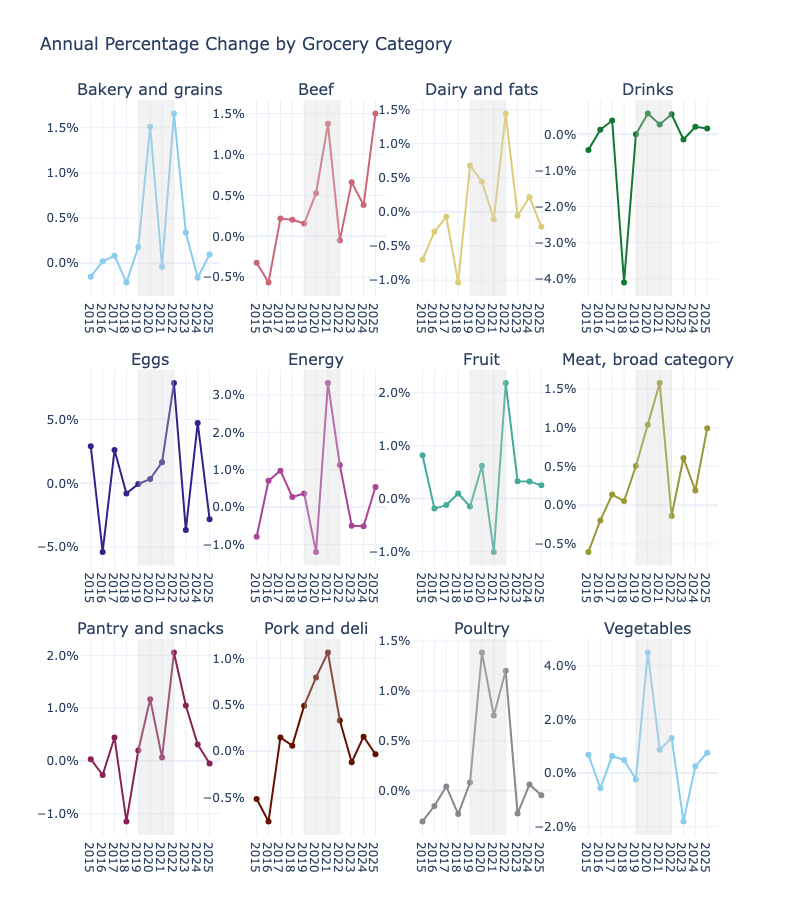

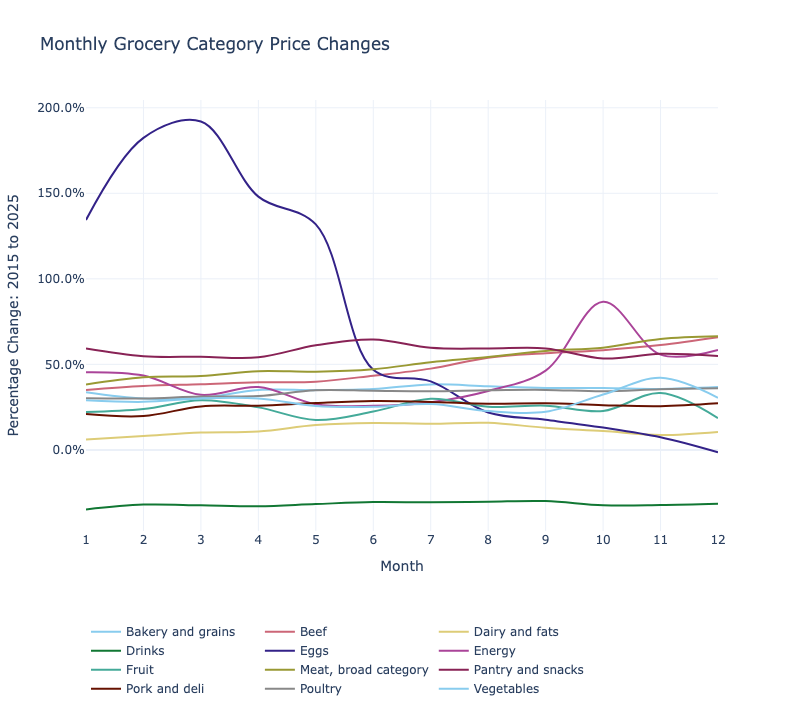

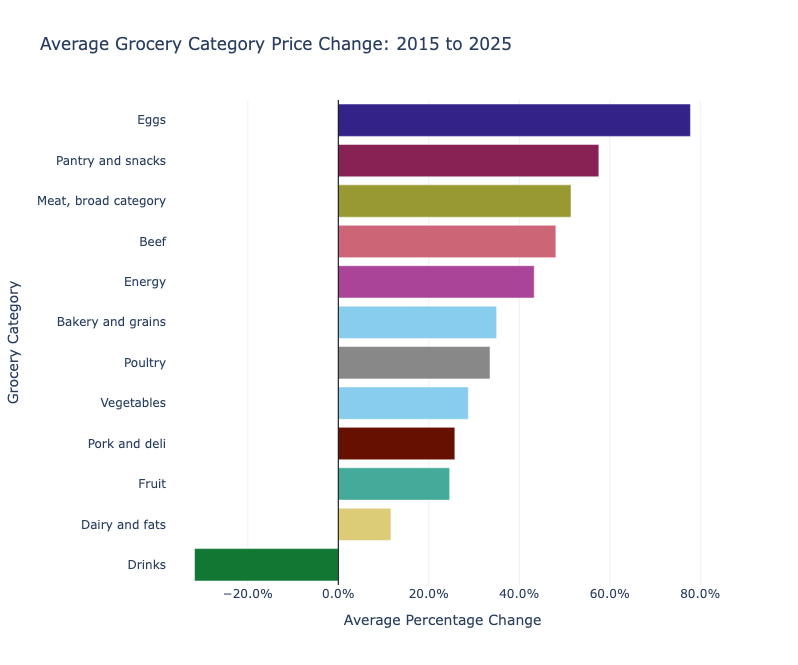

In [10]:
# Creating the df with only the categories and the percentage changing. 
df_pct_cat_monthly = df_project_categories.pct_change()

df_pct_cat_monthly = df_pct_cat_monthly.loc[:, 
    (df_pct_cat_monthly.columns != "Consumer_Price_Index") &
     (df_pct_cat_monthly.columns != "Average_Hourly_Wage")]
# Dropping the first row (Null row, no previous data)

df_pct_cat_monthly = df_pct_cat_monthly.dropna(how="all")

# Creating pivot table per year.

df_pct_pivot = df_pct_cat_monthly.pivot_table(
    index = df_pct_cat_monthly.index.year,
    aggfunc="mean")

# Creating interactive plots for each category.

fig = make_subplots(
    rows=3,
    cols=4,
    subplot_titles=df_pct_pivot.columns,
    horizontal_spacing=0.04,
    vertical_spacing=0.10
)

for i, column in enumerate(df_pct_pivot.columns):
    row = (i // 4) + 1
    col = (i % 4) + 1

    fig.add_trace(
        go.Scatter(
            x=df_pct_pivot.index,
            y=df_pct_pivot[column],
            mode="lines+markers",
            name=column,
            line=dict(color=category_colors[column], width=2),
            marker=dict(color=category_colors[column]),
            hovertemplate=(
                f"Category: {column}<br>"
                "Year: %{x}<br>"
                "Change: %{y:.2%}"
                "<extra></extra>"
            )
        ),
        row=row,
        col=col
    )

    fig.add_vrect(
        x0=2019,
        x1=2022,
        fillcolor="lightgray",
        opacity=0.30,
        line_width=0,
        row=row,
        col=col
    )

fig.update_layout(
    title="Annual Percentage Change by Grocery Category",
    width=1400,
    height=900,
    template="plotly_white",
    showlegend=False
)

fig.update_xaxes(dtick=1)
fig.update_yaxes(tickformat=".1%")

fig.show()

## These plots I created using AI because they are interactive. 

# Answering the question. 

# Gathering values from 2015 to 2025

df_price_changes = df_project_categories.loc[((df_project_categories.index.year == 2015) | (df_project_categories.index.year == 2025)), :]

df_price_changes = df_price_changes.loc[:, 
    (df_price_changes.columns != "Consumer_Price_Index") &
    (df_price_changes.columns != "Average_Hourly_Wage")]

# Creating one df for each year

price_2015 = df_price_changes[df_price_changes.index.year == 2015].copy()
price_2025 = df_price_changes[df_price_changes.index.year == 2025].copy()

price_2015.index = price_2015.index.month
price_2025.index = price_2025.index.month

# Gathering the change between months of both years. 

monthly_difference = (price_2025 - price_2015)
monthly_change_pct = monthly_difference / price_2015
monthly_change_pct

# Plotting

fig = go.Figure()

for column in monthly_change_pct.columns:
    fig.add_trace(
        go.Scatter(
            x=monthly_change_pct.index,
            y=monthly_change_pct[column],
            mode="lines",
            name=column,
            line=dict(color=category_colors[column], width=2),
            line_shape="spline",
            hovertemplate=(
                f"Category: {column}<br>"
                "Month: %{x}<br>"
                "Change: %{y:.2%}"
                "<extra></extra>"
            )
        )
    )

fig.update_layout(
    title="Monthly Grocery Category Price Changes",
    width=1200,
    height=700,
    xaxis_title="Month",
    yaxis_title="Percentage Change: 2015 to 2025",
    xaxis=dict(dtick=1),
    yaxis=dict(tickformat=".1%"),
    hovermode="closest",
    template="plotly_white",
    legend=dict(
        orientation="h",
        y=-0.20,
        x=0
    ),
    margin=dict(b=130)
)

fig.show()

### These plots I created using AI because they are interactive. 


# Ranking the mean per category. 

monthly_change_pct_mean = monthly_change_pct.mean()

monthly_change_pct_mean.sort_values(ascending=False)

# Plotting the mean final.
ranked_categories = (
    monthly_change_pct_mean
    .sort_values(ascending=True)
    .rename("average_percentage_change")
    .reset_index()
)

ranked_categories.columns = [
    "category",
    "average_percentage_change"
]

fig = go.Figure()

fig.add_trace(
    go.Bar(
        x=ranked_categories["average_percentage_change"],
        y=ranked_categories["category"],
        orientation="h",
        marker_color=[
            category_colors[category]
            for category in ranked_categories["category"]
        ],
        hovertemplate=(
            "Category: %{y}<br>"
            "Average change: %{x:.2%}"
            "<extra></extra>"
        )
    )
)

fig.update_layout(
    title="Average Grocery Category Price Change: 2015 to 2025",
    xaxis_title="Average Percentage Change",
    yaxis_title="Grocery Category",
    xaxis=dict(tickformat=".1%"),
    template="plotly_white",
    width=1200,
    height=650,
    hovermode="closest"
)

fig.add_vline(
    x=0,
    line_width=1,
    line_color="black"
)

fig.show()

### Question 2: Which grocery categories were most affected during periods of high inflation?

date
2015-01-01         NaN
2015-02-01         NaN
2015-03-01         NaN
2015-04-01         NaN
2015-05-01         NaN
                ...   
2025-08-01    2.898853
2025-09-01    3.008767
2025-10-01    2.846509
2025-11-01    2.708110
2025-12-01    2.593164
Name: Consumer_Price_Index, Length: 132, dtype: float64
                      n_items  baseline  usd_change_high  pct_change_high  \
category                                                                    
Eggs                        1      1.40             1.22            87.51   
Energy                      8     18.75             7.33            39.09   
Pantry and snacks           1      0.59             0.17            29.32   
Meat, broad category        3     13.53             3.90            28.84   
Poultry                     3      5.94             1.61            27.17   
Beef                        9     49.79            11.69            23.49   
Pork and deli               6     23.46             5.35            22

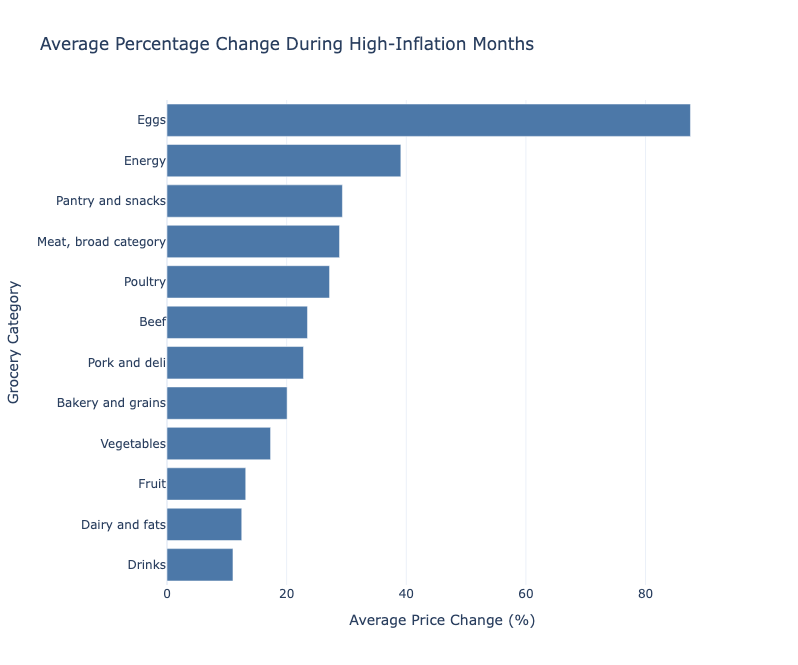

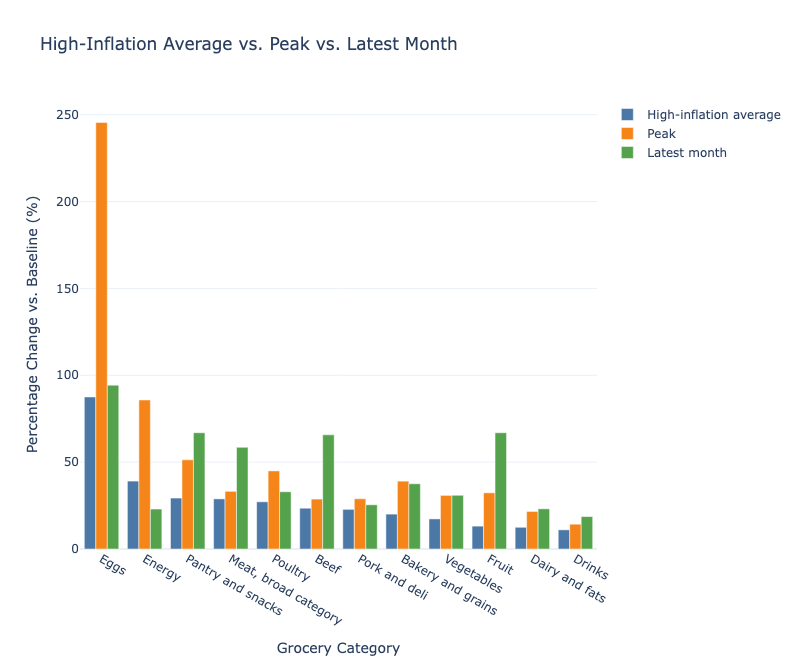

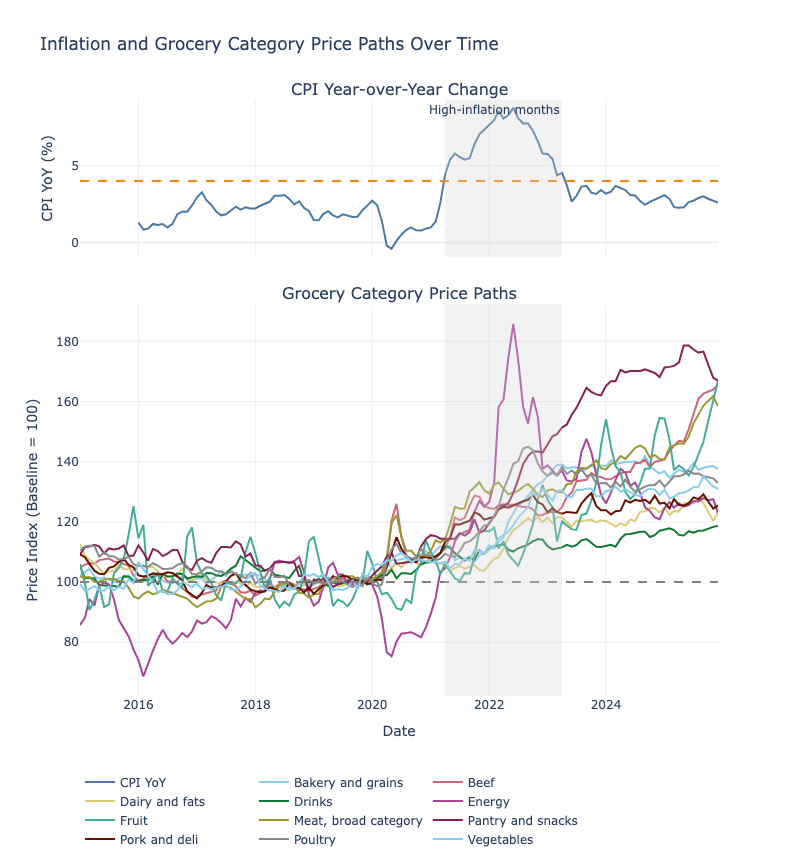

In [11]:
item_to_cat = (df_groceries[["item", "category"]]
               .drop_duplicates()
               .set_index("item")["category"]
               .reindex(df_groceries__items.columns))

basket = df_groceries__items.T.groupby(item_to_cat).sum().T
n_items = item_to_cat.value_counts()

# 2. High-inflation months (same CPI flag as before) -- 
# 4% given the inflation rates have been generally steady at 2-3% historically / allows us to see impact of COVID

THRESHOLD = 4.0
cpi_yoy = df_index["Consumer_Price_Index"].pct_change(12) * 100
high_months = cpi_yoy[cpi_yoy >= THRESHOLD].index

print(cpi_yoy)

# 3. Baseline period
# justification for 2019: it is the most recent year before COVID-19 that we believe is most appropriate for baseline
# also shows the impact of COVID-19

BASE_START, BASE_END = "2019-01-01", "2019-12-01"
baseline = basket.loc[BASE_START:BASE_END].mean()

# 4. Compare against baseline: high-inflation average, peak, and latest month
high_avg = basket.loc[high_months].mean()
peak     = basket.loc[high_months].max()
latest   = basket.iloc[-1]

results = pd.DataFrame({
    "n_items": n_items,
    "baseline": baseline,
    "usd_change_high": high_avg - baseline,
    "pct_change_high": (high_avg / baseline - 1) * 100,
    "usd_change_peak": peak - baseline,
    "pct_change_peak": (peak / baseline - 1) * 100,
    "usd_change_latest": latest - baseline,
    "pct_change_latest": (latest / baseline - 1) * 100,
})

# Dollar change per item, since categories have different numbers of items
results["usd_change_high_per_item"] = results["usd_change_high"] / results["n_items"]

print(results.sort_values("pct_change_high", ascending=False).round(2))
print(results.sort_values("pct_change_peak", ascending = False))
print(peak)


# ______________________________________________________________________________

# Visualization
import matplotlib.pyplot as plt

# Chart 1: Which categories rose the most during high inflation?
order = results.sort_values(
    "pct_change_high",
    ascending=True
)

fig = go.Figure()

fig.add_trace(
    go.Bar(
        x=order["pct_change_high"],
        y=order.index,
        orientation="h",
        marker_color="#4C78A8",
        hovertemplate=(
            "Category: %{y}<br>"
            "Change: %{x:.2f}%"
            "<extra></extra>"
        )
    )
)

fig.update_layout(
    title="Average Percentage Change During High-Inflation Months",
    xaxis_title="Average Price Change (%)",
    yaxis_title="Grocery Category",
    template="plotly_white",
    width=1200,
    height=650,
    hovermode="closest"
)

fig.show()

# Chart 2: High-inflation average vs. peak vs. latest month
# high-inflation average -- take the months of high inflation CPI and average the costs
cmp = (
    results
    .sort_values("pct_change_high", ascending=False)
    [["pct_change_high", "pct_change_peak", "pct_change_latest"]]
)

cmp.columns = [
    "High-inflation average",
    "Peak",
    "Latest month"
]

fig = go.Figure()

comparison_colors = [
    "#4C78A8",
    "#F58518",
    "#54A24B"
]

for column, color in zip(cmp.columns, comparison_colors):
    fig.add_trace(
        go.Bar(
            x=cmp.index,
            y=cmp[column],
            name=column,
            marker_color=color,
            hovertemplate=(
                f"Category: %{{x}}<br>"
                f"{column}: %{{y:.2f}}%"
                "<extra></extra>"
            )
        )
    )

fig.update_layout(
    title="High-Inflation Average vs. Peak vs. Latest Month",
    xaxis_title="Grocery Category",
    yaxis_title="Percentage Change vs. Baseline (%)",
    template="plotly_white",
    width=1200,
    height=650,
    barmode="group",
    hovermode="closest"
)

fig.show()

# Chart 3: Price paths over time (baseline = 100) with CPI inflation above
basket_idx = (
    basket / basket.loc[BASE_START:BASE_END].mean()
) * 100

outliers = ["Eggs"]

fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.08,
    row_heights=[1, 2.5],
    subplot_titles=[
        "CPI Year-over-Year Change",
        "Grocery Category Price Paths"
    ]
)

fig.add_trace(
    go.Scatter(
        x=cpi_yoy.index,
        y=cpi_yoy,
        mode="lines",
        name="CPI YoY",
        line=dict(color="#4C78A8", width=2),
        hovertemplate=(
            "Date: %{x|%b %Y}<br>"
            "CPI YoY: %{y:.2f}%"
            "<extra></extra>"
        )
    ),
    row=1,
    col=1
)

fig.add_hline(
    y=THRESHOLD,
    line_color="#F58518",
    line_dash="dash",
    row=1,
    col=1
)

for column in basket_idx.columns:
    if column not in outliers:
        fig.add_trace(
            go.Scatter(
                x=basket_idx.index,
                y=basket_idx[column],
                mode="lines",
                name=column,
                line=dict(
                    color=category_colors.get(column, "#4C78A8")
                ),
                hovertemplate=(
                    f"Category: {column}<br>"
                    "Date: %{x|%b %Y}<br>"
                    "Index: %{y:.2f}"
                    "<extra></extra>"
                )
            ),
            row=2,
            col=1
        )

fig.add_hline(
    y=100,
    line_color="gray",
    line_dash="dash",
    row=2,
    col=1
)

fig.add_vrect(
    x0=high_months.min(),
    x1=high_months.max(),
    fillcolor="lightgray",
    opacity=0.30,
    line_width=0,
    annotation_text="High-inflation months",
    row=1,
    col=1
)

fig.add_vrect(
    x0=high_months.min(),
    x1=high_months.max(),
    fillcolor="lightgray",
    opacity=0.30,
    line_width=0,
    row=2,
    col=1
)

fig.update_layout(
    title="Inflation and Grocery Category Price Paths Over Time",
    width=1200,
    height=850,
    template="plotly_white",
    hovermode="closest",
    legend=dict(
        orientation="h",
        y=-0.12,
        x=0
    ),
    margin=dict(b=130)
)

fig.update_yaxes(
    title_text="CPI YoY (%)",
    row=1,
    col=1
)

fig.update_yaxes(
    title_text="Price Index (Baseline = 100)",
    row=2,
    col=1
)

fig.update_xaxes(
    title_text="Date",
    row=2,
    col=1
)

fig.show()

### Question 3: Which individual grocery items experienced the largest price increases?

item
All Ham (Excluding Canned Ham and Luncheon Slices)            3.211
All Other Pork (Excluding Canned Ham and Luncheon Slices)     2.991
All Pork Chops                                                3.988
All Uncooked Beef Roasts                                      5.838
All Uncooked Beef Steaks                                      7.530
All Uncooked Other Beef (Excluding Veal)                      4.734
All uncooked ground beef                                      4.675
American processed cheese                                     4.944
Automotive diesel fuel                                        2.964
Bacon, sliced                                                 5.589
Bananas                                                       0.583
Beans, dried, any type, all sizes                             1.452
Bread, white, pan                                             1.479
Bread, whole wheat, pan                                       1.948
Cheddar cheese, natural                    

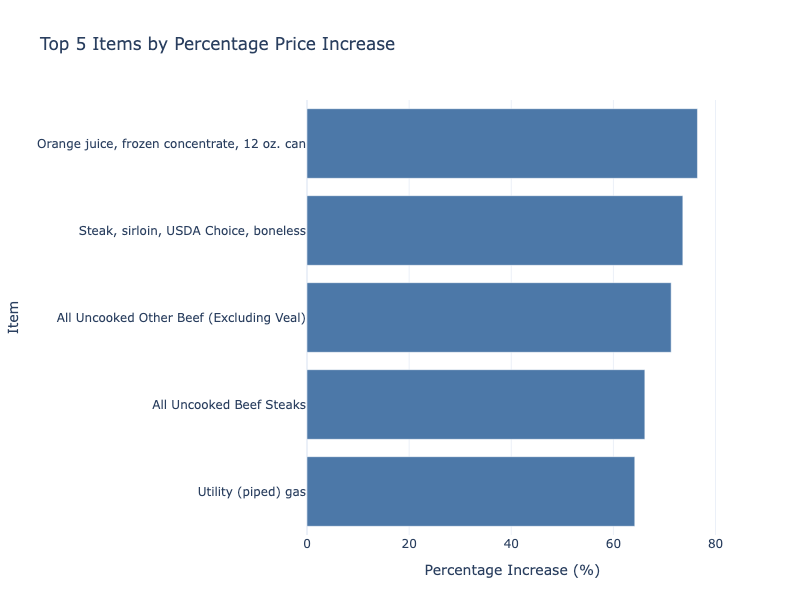

In [12]:
# Step 1: first and last price of every item
first_price = df_groceries__items.iloc[0]
last_price  = df_groceries__items.iloc[-1]

print(first_price, last_price)

# Step 2: build a results table with both dollar and percent change
item_results = pd.DataFrame({"first_price": first_price, "last_price": last_price})
item_results["usd_change"] = item_results["last_price"] - item_results["first_price"]
item_results["pct_increase"] = (item_results["last_price"] / item_results["first_price"] - 1) * 100

print(item_results)

# Step 3: add category and unit so each number has context
item_info = (df_groceries[["item", "category", "unit"]]
             .drop_duplicates()
             .set_index("item"))
item_results = item_results.join(item_info)

print(item_results)

# Step 4: rank by percent increase and keep the top 10
item_results = item_results.sort_values("pct_increase", ascending=False)
top5 = item_results.head(5)
print(top5.round(2))


# Step 5: rebase the top 10 to Jan 2015 = 100 for the line chart
top5_names = top5.index
rebased = df_groceries__items[top5_names] / df_groceries__items[top5_names].iloc[0] * 100

# Step 6: draw both charts side by side
top5_sorted = top5.sort_values(
    "pct_increase",
    ascending=True
)

fig = go.Figure()

fig.add_trace(
    go.Bar(
        x=top5_sorted["pct_increase"],
        y=top5_sorted.index,
        orientation="h",
        marker_color="#4C78A8",
        hovertemplate=(
            "Item: %{y}<br>"
            "Percentage increase: %{x:.2f}%"
            "<extra></extra>"
        )
    )
)

fig.update_layout(
    title="Top 5 Items by Percentage Price Increase",
    xaxis_title="Percentage Increase (%)",
    yaxis_title="Item",
    template="plotly_white",
    width=1200,
    height=600,
    hovermode="closest"
)

fig.show()

### Question 4: Did all grocery categories increase at the same rate as overall inflation?

QUESTION 4 RESULTS
CPI growth: 35.70%
                      Category Growth (%)  CPI Growth (%)  \
Eggs                                68.54            35.7   
Pantry and snacks                   57.57            35.7   
Meat, broad category                51.31            35.7   
Beef                                48.00            35.7   
Energy                              42.30            35.7   
Bakery and grains                   34.97            35.7   
Poultry                             33.51            35.7   
Vegetables                          28.75            35.7   
Pork and deli                       25.72            35.7   
Fruit                               24.46            35.7   
Dairy and fats                      11.57            35.7   
Drinks                             -31.80            35.7   

                      Difference from CPI (percentage points)  Faster Than CPI  
Eggs                                                    32.83             True  
Pantry

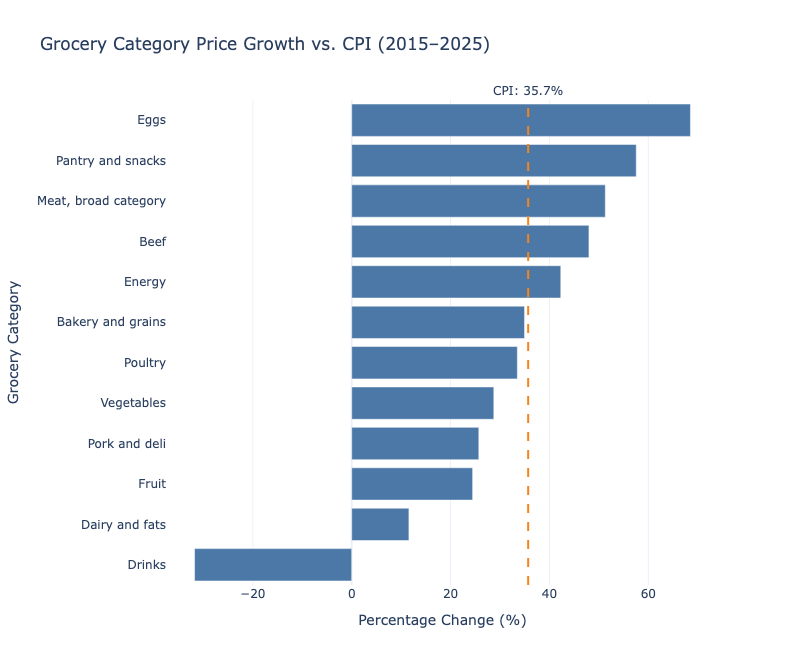

In [13]:
# Calculating the annual average

annual_means = (
    df_project_categories
    .groupby(df_project_categories.index.year)
    .mean()
)


# Calculating percentage change from 2015 to 2025

total_change_pct = (
    (annual_means.loc[2025] / annual_means.loc[2015] - 1) * 100
)


# Separating grocery categories from CPI and wages

category_growth = total_change_pct.drop(
    ["Consumer_Price_Index", "Average_Hourly_Wage"]
)

cpi_growth = total_change_pct["Consumer_Price_Index"]

wage_growth = total_change_pct["Average_Hourly_Wage"]

q4_results = pd.DataFrame({
    "Category Growth (%)": category_growth
})

q4_results["CPI Growth (%)"] = cpi_growth

q4_results["Difference from CPI (percentage points)"] = (
    q4_results["Category Growth (%)"] - cpi_growth
)

q4_results["Faster Than CPI"] = (
    q4_results["Difference from CPI (percentage points)"] > 0
)

q4_results = q4_results.sort_values(
    "Category Growth (%)",
    ascending=False
)

print("QUESTION 4 RESULTS")
print(f"CPI growth: {cpi_growth:.2f}%")
print(q4_results.round(2))


# Interactive plot for Question 4

# Grocery category growth compared with CPI

q4_plot = q4_results.sort_values(
    "Category Growth (%)",
    ascending=True
)

fig_q4 = go.Figure()

fig_q4.add_trace(
    go.Bar(
        x=q4_plot["Category Growth (%)"],
        y=q4_plot.index,
        orientation="h",
        marker_color="#4C78A8",
        hovertemplate=(
            "Category: %{y}<br>"
            "Growth: %{x:.2f}%"
            "<extra></extra>"
        )
    )
)

fig_q4.add_vline(
    x=cpi_growth,
    line_color="#F58518",
    line_dash="dash",
    line_width=2,
    annotation_text=f"CPI: {cpi_growth:.1f}%",
    annotation_position="top"
)

fig_q4.update_layout(
    title="Grocery Category Price Growth vs. CPI (2015–2025)",
    xaxis_title="Percentage Change (%)",
    yaxis_title="Grocery Category",
    template="plotly_white",
    width=1100,
    height=650,
    hovermode="closest"
)

fig_q4.show()

### Question 5: Which grocery categories increased faster than average hourly wages?

QUESTION 5 RESULTS
Average hourly wage growth: 45.71%
                      Category Growth (%)  Average Hourly Wage Growth (%)  \
Eggs                                68.54                           45.71   
Pantry and snacks                   57.57                           45.71   
Meat, broad category                51.31                           45.71   
Beef                                48.00                           45.71   
Energy                              42.30                           45.71   
Bakery and grains                   34.97                           45.71   
Poultry                             33.51                           45.71   
Vegetables                          28.75                           45.71   
Pork and deli                       25.72                           45.71   
Fruit                               24.46                           45.71   
Dairy and fats                      11.57                           45.71   
Drinks                

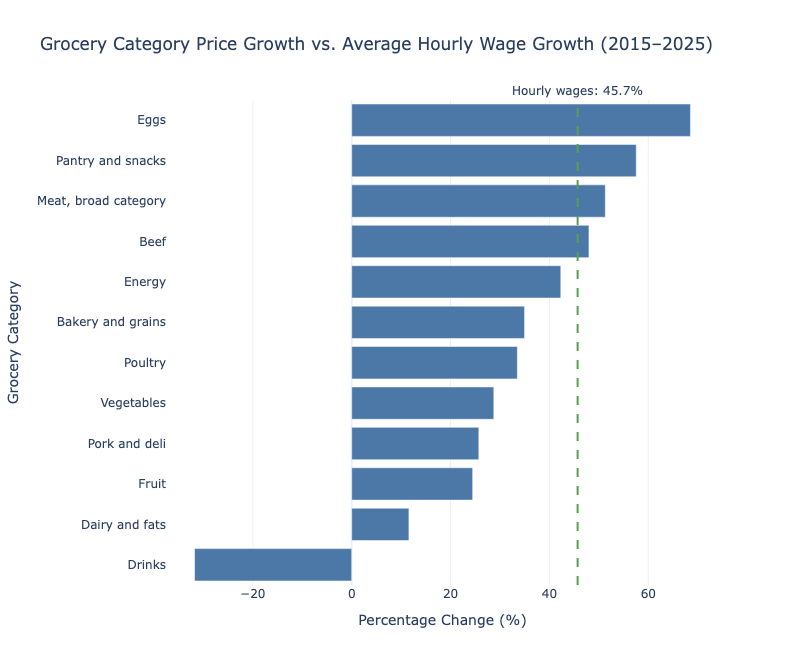

In [14]:
q5_results = pd.DataFrame({
    "Category Growth (%)": category_growth
})

q5_results["Average Hourly Wage Growth (%)"] = wage_growth

q5_results["Difference from Wages (percentage points)"] = (
    q5_results["Category Growth (%)"] - wage_growth
)

q5_results["Faster Than Wages"] = (
    q5_results["Difference from Wages (percentage points)"] > 0
)

q5_results = q5_results.sort_values(
    "Category Growth (%)",
    ascending=False
)

print("QUESTION 5 RESULTS")
print(f"Average hourly wage growth: {wage_growth:.2f}%")
print(q5_results.round(2))


# Selecting categories that increased faster than wages

faster_categories = q5_results[
    q5_results["Faster Than Wages"]
]

print("CATEGORIES THAT INCREASED FASTER THAN WAGES")

print(
    faster_categories[
        [
            "Category Growth (%)",
            "Difference from Wages (percentage points)"
        ]
    ].round(2)
)

print(
    f"Total: {len(faster_categories)} out of "
    f"{len(q5_results)} categories increased faster than wages."
)


# Interactive plot for Question 5

q5_plot = q5_results.sort_values(
    "Category Growth (%)",
    ascending=True
)

fig_q5 = go.Figure()

fig_q5.add_trace(
    go.Bar(
        x=q5_plot["Category Growth (%)"],
        y=q5_plot.index,
        orientation="h",
        marker_color="#4C78A8",
        hovertemplate=(
            "Category: %{y}<br>"
            "Growth: %{x:.2f}%"
            "<extra></extra>"
        )
    )
)

fig_q5.add_vline(
    x=wage_growth,
    line_color="#54A24B",
    line_dash="dash",
    line_width=2,
    annotation_text=f"Hourly wages: {wage_growth:.1f}%",
    annotation_position="top"
)

fig_q5.update_layout(
    title=(
        "Grocery Category Price Growth vs. "
        "Average Hourly Wage Growth (2015–2025)"
    ),
    xaxis_title="Percentage Change (%)",
    yaxis_title="Grocery Category",
    template="plotly_white",
    width=1100,
    height=650,
    hovermode="closest"
)

fig_q5.show()